# Step 1 : Import Libraries

In [1]:
import pandas as pd

In [2]:
import numpy as np

# Step 2 : Load Dataset

In [3]:
df= pd.read_csv("../Dataset/Bengaluru_House_Data.csv") 

# Step 3 : Display Dataset

In [4]:
df.head(5)

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [5]:
df.tail(5)

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.0
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.0
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.0
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.0
13319,Super built-up Area,Ready To Move,Doddathoguru,1 BHK,NaN,550,1.0,1.0,17.0


In [6]:
df.sample(5)

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
3188,Super built-up Area,Ready To Move,Green Domain Layout,3 BHK,NaN,2100,3.0,3.0,170.0
4273,Plot Area,Ready To Move,Gottigere,1 Bedroom,NaN,812,1.0,1.0,26.0
2828,Super built-up Area,Ready To Move,Srigandada Kaval,2 BHK,NaN,1200,2.0,0.0,53.0
8282,Built-up Area,Ready To Move,Kalyan nagar,2 BHK,Saacela,1190,2.0,1.0,60.0
7432,Built-up Area,Ready To Move,Brookefield,2 BHK,NaN,1230,2.0,3.0,55.0


# Step 4: Dataset Understanding

## Check Dataset Shape

In [7]:
df.shape

(13320, 9)

## The dataset contains 13,320 records and 9 features, making it suitable for building a house price prediction model.

## Display Column Names

In [8]:
df.columns

Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='str')

## Check Data Types

In [9]:
df.dtypes

area_type           str
availability        str
location            str
size                str
society             str
total_sqft          str
bath            float64
balcony         float64
price           float64
dtype: object

## Dataset Information

In [10]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 1.6 MB
None


### There are 609 missing values in the balcony column.

## Statistical Summary

In [11]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


## Identify Target Variable

### Target Variable (y) = price

## Identify Feature Variables

##   [[area_type , availability , location , size , society , total_sqft , bath , balcony ]]

# Step 5 : Missing Value Analysis

### Check Missing Values

In [12]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

### Total missing values

In [13]:
df.isnull().sum().sum()

np.int64(6201)

### Create Missing Value Summary Table

In [14]:
missing_df=pd.DataFrame({
    "Missing_values" : df.isnull().sum(),
    "Percentage" : (df.isnull().sum()/len(df)) * 100
})

In [15]:
missing_df.sort_values(by='Percentage',ascending=False)

,Missing_values,Percentage
society,5502,41.306306
balcony,609,4.572072
bath,73,0.548048
size,16,0.120120
location,1,0.007508
area_type,0,0.000000
availability,0,0.000000
total_sqft,0,0.000000
price,0,0.000000


### Visualize Missing Values

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

Text(0, 0.5, 'Missing Percentage')

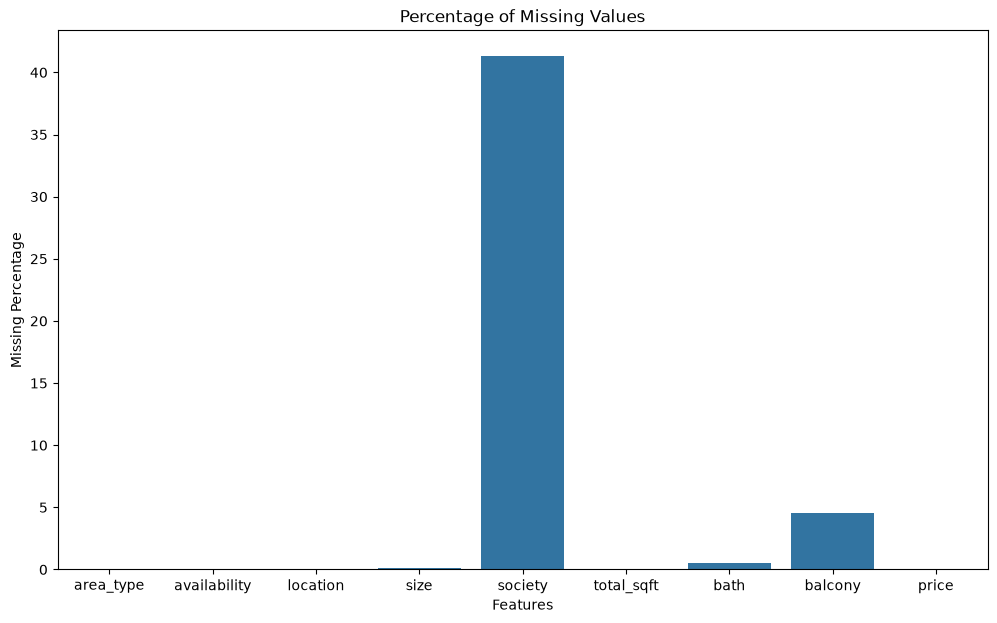

In [78]:
plt.figure(figsize=(12,7))

sns.barplot(x=missing_df.index, y = missing_df["Percentage"])

plt.xticks(rotation=0)
plt.title("Percentage of Missing Values")
plt.xlabel("Features")
plt.ylabel("Missing Percentage")

# Step 6 : Handle Missing Values

### 6.1 Analyze society column

In [18]:
df['society'].isnull().sum()

np.int64(5502)

In [19]:
df['society'].nunique()

2688

## Best Decision

In [20]:
df.drop('society', axis=1, inplace=True)

In [21]:
print(df.columns)

Index(['area_type', 'availability', 'location', 'size', 'total_sqft', 'bath',
       'balcony', 'price'],
      dtype='str')


### The society column had many missing values (around 41%) and too many unique categories. It was difficult to preprocess and was not necessary for improving the prediction, so we removed it.

## 6.2 Clean location Column

In [22]:
df['location'].isnull().sum()

np.int64(1)

### Drop That Single Row

In [23]:
df.dropna(subset=['location'], inplace=True)

### Remove Extra Spaces

In [24]:
df['location'] = df['location'].str.strip()

In [25]:
df['location'].nunique()

1294

## 6.3 Clean size Column

In [26]:
df['size'].unique()

<ArrowStringArray>
[     '2 BHK',  '4 Bedroom',      '3 BHK',      '4 BHK',  '6 Bedroom',
  '3 Bedroom',      '1 BHK',       '1 RK',  '1 Bedroom',  '8 Bedroom',
  '2 Bedroom',  '7 Bedroom',      '5 BHK',      '7 BHK',      '6 BHK',
  '5 Bedroom',     '11 BHK',      '9 BHK',          nan,  '9 Bedroom',
     '27 BHK', '10 Bedroom', '11 Bedroom',     '10 BHK',     '19 BHK',
     '16 BHK', '43 Bedroom',     '14 BHK',      '8 BHK', '12 Bedroom',
     '13 BHK', '18 Bedroom']
Length: 32, dtype: str

### Check Missing Values

In [27]:
df['size'].isnull().sum()

np.int64(16)

In [28]:
df[df['size'].isnull()]

,area_type,availability,location,size,total_sqft,bath,balcony,price
579,Plot Area,Immediate Possession,Sarjapur Road,NaN,1200 - 2400,NaN,NaN,34.185
1775,Plot Area,Immediate Possession,IVC Road,NaN,2000 - 5634,NaN,NaN,124.000
2264,Plot Area,Immediate Possession,Banashankari,NaN,2400,NaN,NaN,460.000
2809,Plot Area,Immediate Possession,Sarjapur Road,NaN,1200 - 2400,NaN,NaN,28.785
2862,Plot Area,Immediate Possession,Devanahalli,NaN,1500 - 2400,NaN,NaN,46.800
5333,Plot Area,Immediate Possession,Devanahalli,NaN,2100 - 5405,NaN,NaN,177.115
6423,Plot Area,Immediate Possession,Whitefield,NaN,2324,NaN,NaN,26.730
6636,Plot Area,Immediate Possession,Jigani,NaN,1500,NaN,NaN,25.490
6719,Plot Area,Immediate Possession,Hoskote,NaN,800 - 2660,NaN,NaN,28.545
7680,Plot Area,Immediate Possession,Kasavanhalli,NaN,5000,NaN,NaN,400.000


### Drop these rows

In [29]:
df.dropna(subset=['size'], inplace=True)

### Create a New BHK Column

In [30]:
df['bhk'] = df['size'].apply(lambda x: int(x.split()[0]))

In [31]:
df[['size', 'bhk']].sample(10)

,size,bhk
5414,3 BHK,3
3933,2 BHK,2
7532,3 BHK,3
7112,3 BHK,3
7883,4 BHK,4
12763,3 BHK,3
3463,3 BHK,3
1221,2 BHK,2
3137,2 BHK,2
4815,2 BHK,2


In [32]:
df['bhk'].dtype

dtype('int64')

### Remove original size column

In [33]:
df.drop(columns = 'size', inplace=True)

### The size column was removed because its information was already used to create the BHK feature.

## 6.4 Clean total_sqft column

In [34]:
df['total_sqft'].sample(20)

10378     1318
1424      1330
9320      1145
3360      1230
12616      550
1819      1188
3341       900
10139     1160
4404      1037
4308     10000
1767      1420
5161      1820
4710      1464
2208      3526
5508      1041
8967      2050
11604     1700
6130      1305
9933      3210
7505      2275
Name: total_sqft, dtype: str

In [35]:
df['total_sqft'].dtype

<StringDtype(na_value=nan)>

In [36]:
def is_float(x):
    try:
        float(x)
    except:
        return False
    return True

In [37]:
df[~df['total_sqft'].apply(is_float)].head(20)

,area_type,availability,location,total_sqft,bath,balcony,price,bhk
30,Super built-up Area,19-Dec,Yelahanka,2100 - 2850,4.0,0.0,186.000,4
56,Built-up Area,20-Feb,Devanahalli,3010 - 3410,NaN,NaN,192.000,4
81,Built-up Area,18-Oct,Hennur Road,2957 - 3450,NaN,NaN,224.500,4
122,Super built-up Area,18-Mar,Hebbal,3067 - 8156,4.0,0.0,477.000,4
137,Super built-up Area,19-Mar,8th Phase JP Nagar,1042 - 1105,2.0,0.0,54.005,2
165,Super built-up Area,18-Dec,Sarjapur,1145 - 1340,2.0,0.0,43.490,2
188,Super built-up Area,Ready To Move,KR Puram,1015 - 1540,2.0,0.0,56.800,2
224,Super built-up Area,19-Dec,Devanahalli,1520 - 1740,NaN,NaN,74.820,3
410,Super built-up Area,Ready To Move,Kengeri,34.46Sq. Meter,1.0,0.0,18.500,1
549,Super built-up Area,18-Sep,Hennur Road,1195 - 1440,2.0,0.0,63.770,2


### Handle Range Values

In [38]:
def sqft_to_num(x):
    numbers = x.split('-')

    if len(numbers) == 2:
        return (float(numbers[0]) + float(numbers[1])) / 2
    try:
        return float(x)
    except:
        return None

### This is a common and reasonable approach because the exact area is not known, but the midpoint is a good estimate.

In [39]:
df['total_sqft'] = df['total_sqft'].apply(sqft_to_num)

In [40]:
df[df['total_sqft'].isnull()]

,area_type,availability,location,total_sqft,bath,balcony,price,bhk
410,Super built-up Area,Ready To Move,Kengeri,NaN,1.0,0.0,18.50,1
648,Built-up Area,Ready To Move,Arekere,NaN,9.0,NaN,265.00,9
775,Built-up Area,Ready To Move,Basavanagara,NaN,2.0,1.0,93.00,1
872,Super built-up Area,Ready To Move,Singapura Village,NaN,2.0,NaN,45.00,2
1019,Plot Area,18-Mar,Marathi Layout,NaN,1.0,0.0,110.00,1
1086,Plot Area,19-Mar,Narasapura,NaN,2.0,2.0,29.50,2
1400,Super built-up Area,Ready To Move,Chamrajpet,NaN,9.0,1.0,296.00,9
1712,Plot Area,Ready To Move,Singena Agrahara,NaN,3.0,1.0,95.00,3
1743,Super built-up Area,19-Mar,Hosa Road,NaN,3.0,1.0,115.00,3
1821,Plot Area,Ready To Move,Sarjapur,NaN,3.0,1.0,76.00,3


### Drop these rows

In [41]:
df.dropna(subset=['total_sqft'], inplace=True)

In [42]:
df['total_sqft'].dtype

dtype('float64')

# Step 7 : Clean bath, balcony, & Duplicates Columns

## 7.1 Clean bath

In [43]:
df['bath'].isnull().sum()

np.int64(57)

In [44]:
df['bath'] = df['bath'].fillna(df['bath'].median())

In [45]:
df['bath'].isnull().sum()

np.int64(0)

## 7.2 Clean balcony

In [46]:
df['balcony'].isnull().sum()

np.int64(589)

In [47]:
df['balcony'] = df['balcony'].fillna(df['balcony'].median())

In [48]:
df['balcony'].isnull().sum()

np.int64(0)

## 7.3 Check Duplicate Rows

In [49]:
df.duplicated().sum()

np.int64(570)

In [50]:
df.drop_duplicates(inplace=True)

In [51]:
df.duplicated().sum()

np.int64(0)

## Final Missing Value Check

In [52]:
df.isnull().sum()

area_type       0
availability    0
location        0
total_sqft      0
bath            0
balcony         0
price           0
bhk             0
dtype: int64

## Final Data Types

In [53]:
df.dtypes

area_type           str
availability        str
location            str
total_sqft      float64
bath            float64
balcony         float64
price           float64
bhk               int64
dtype: object

# Step 8 : Outlier Analysis

### An outlier is a data point that is very different from the rest of the data.

## 8.1 Create Price Per Sqft Feature

In [54]:
df['price_per_sqft'] = (df['price'] * 100000) / df['total_sqft']

In [55]:
df[['price','total_sqft','price_per_sqft']].sample(5)

,price,total_sqft,price_per_sqft
13258,59.00,877.0,6727.480046
1736,93.36,1330.0,7019.548872
8935,125.00,1695.0,7374.631268
6701,70.00,1230.0,5691.056911
12140,56.81,1196.0,4750.000000


In [56]:
df['price_per_sqft'].describe()

count    1.268700e+04
mean     8.039650e+03
std      1.088610e+05
min      2.678298e+02
25%      4.300000e+03
50%      5.490465e+03
75%      7.407407e+03
max      1.200000e+07
Name: price_per_sqft, dtype: float64

In [57]:
df.shape

(12687, 9)

## 8.2 Visualize Distribution

Text(0.5, 1.0, 'Price Per Sqft Distribution')

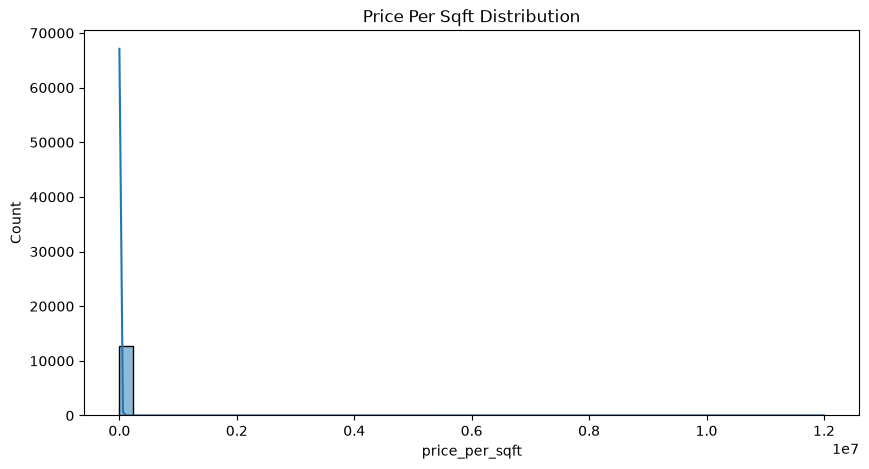

In [58]:
plt.figure(figsize=(10,5))
sns.histplot(df['price_per_sqft'], bins=50,kde=True)
plt.title("Price Per Sqft Distribution")

### Most houses have a price per square foot between ₹3,000 and ₹10,000. Some houses have very high values, so the graph is skewed to the right. This means there are some outliers in the dataset.

## Box Plot

Text(0.5, 1.0, 'Price Per Sqft Boxplot')

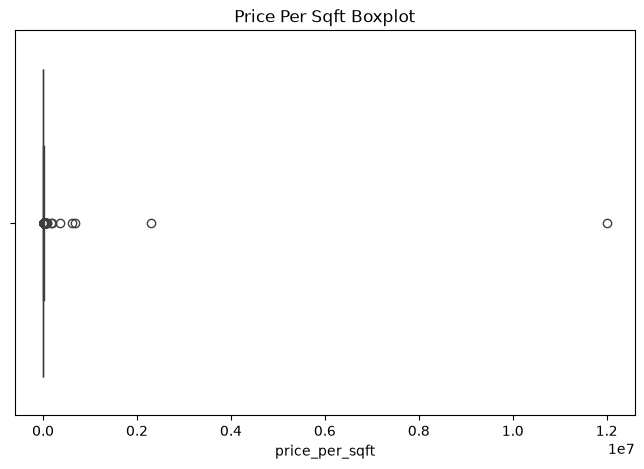

In [59]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['price_per_sqft'])
plt.title("Price Per Sqft Boxplot")

### A boxplot summarizes the distribution of numerical data by showing the median, quartiles, and potential outliers. Values outside the whiskers are considered possible outliers.

## 8.3 : Remove Outliers using Location-wise Mean ± Standard Deviation

In [60]:
def remove_outliers(df):
    df_out = pd.DataFrame()

    for location, location_df in df.groupby('location'):

        mean = location_df.price_per_sqft.mean()
        std = location_df.price_per_sqft.std()

        filtered_df = location_df[
            (location_df.price_per_sqft >= (mean - std)) & (location_df.price_per_sqft <= (mean + std))]

        df_out = pd.concat([df_out, filtered_df], ignore_index=True)

    return df_out

In [61]:
df.shape

(12687, 9)

## Now remove outlier

In [62]:
df = remove_outliers(df)

In [63]:
df.shape

(9964, 9)

### Check Again

Text(0.5, 1.0, 'Price Per Sqft Distribution After Outlier Removal')

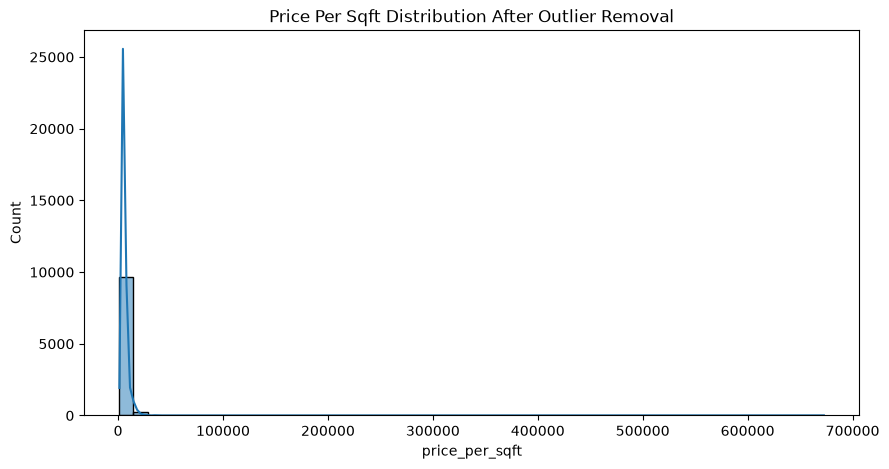

In [64]:
plt.figure(figsize=(10,5))
sns.histplot(df['price_per_sqft'], bins=50, kde = True)
plt.title("Price Per Sqft Distribution After Outlier Removal")

### After removing outliers, the distribution became more compact. Most extreme values were removed, making the data cleaner for model training.

Text(0.5, 1.0, 'Price Per Sqft Boxplot After Outlier Removal')

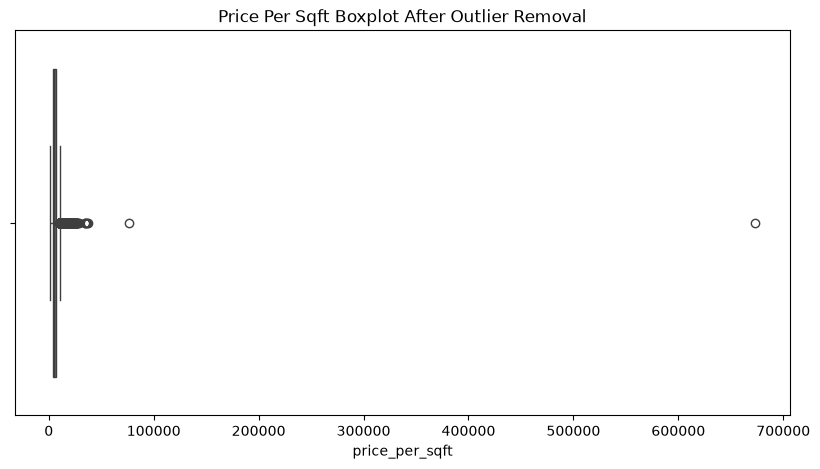

In [65]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df['price_per_sqft'])
plt.title("Price Per Sqft Boxplot After Outlier Removal")

### The number of outliers decreased after applying the location-wise outlier removal method. A few outliers still remain, but the overall data quality has improved.

## 8.4 Domain Knowledge Outlier Removal

In [66]:
df = df[df['total_sqft'] / df['bhk'] >= 300]

In [67]:
print(df.shape)

(9688, 9)


##  Visualize Again 

Text(0.5, 1.0, 'Price Per Sqft Distribution After BHK Outlier Removal')

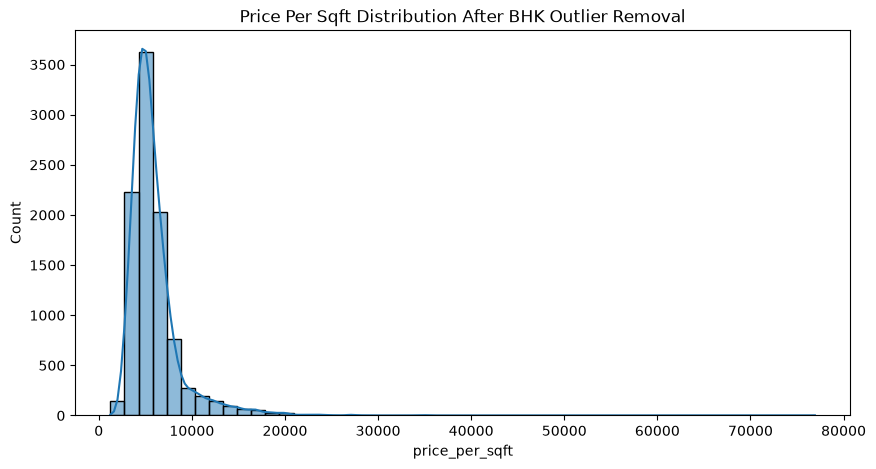

In [68]:
plt.figure(figsize=(10,5))
sns.histplot(df['price_per_sqft'], bins=50, kde=True)
plt.title("Price Per Sqft Distribution After BHK Outlier Removal")

### After removing unrealistic BHK records, the distribution became more consistent. Most houses are concentrated within a normal price range.

Text(0.5, 1.0, 'Price Per Sqft Boxplot After BHK Outlier Removal')

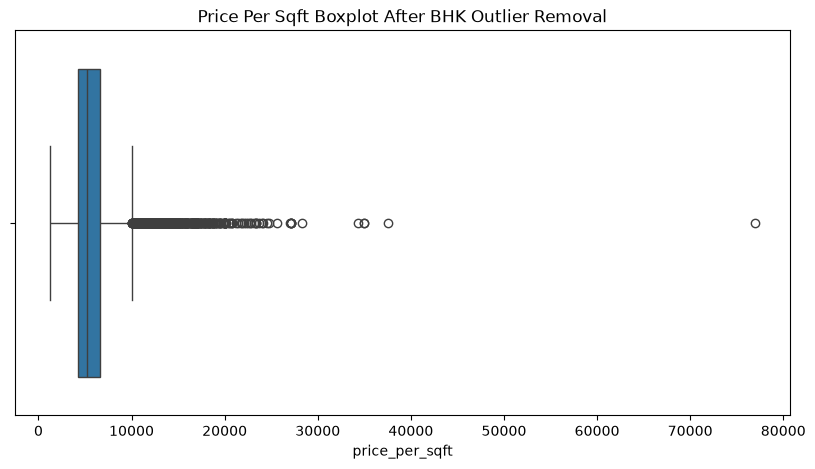

In [69]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df['price_per_sqft'])
plt.title("Price Per Sqft Boxplot After BHK Outlier Removal")

### The boxplot shows fewer extreme values after removing invalid BHK records. The dataset is now cleaner and more suitable for model training.

### 8.5 : Drop Unnecessary Column

In [70]:
df.drop('price_per_sqft', axis=1, inplace=True)

In [71]:
df.sample(4)

,area_type,availability,location,total_sqft,bath,balcony,price,bhk
2356,Super built-up Area,Ready To Move,Dodda Nekkundi Extension,1148.0,2.0,2.0,60.00,2
9621,Super built-up Area,Ready To Move,Whitefield,1453.0,2.0,2.0,58.00,3
4008,Super built-up Area,18-May,Horamavu Agara,1176.0,2.0,1.0,37.62,3
9472,Built-up Area,Ready To Move,Whitefield,2500.0,4.0,1.0,420.00,4


# Step 9 : Save Final Clean Dataset

In [72]:
df.to_csv("../Dataset/cleaned_data.csv", index=False)

# Step 10: Verify Saved Dataset

In [73]:
clean_df = pd.read_csv("../Dataset/cleaned_data.csv")

In [74]:
clean_df.head()

,area_type,availability,location,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,Ready To Move,1st Block BEL Layout,1540.0,3.0,2.0,85.0,3
1,Built-up Area,Ready To Move,1st Block BEL Layout,1800.0,5.0,1.0,250.0,4
2,Super built-up Area,Ready To Move,1st Block HBR Layout,600.0,1.0,0.0,45.0,1
3,Built-up Area,Ready To Move,1st Block HBR Layout,3150.0,4.0,2.0,150.0,4
4,Plot Area,Ready To Move,1st Block HRBR Layout,2400.0,7.0,3.0,355.0,7


In [75]:
clean_df.shape

(9688, 8)

In [76]:
clean_df.isnull().sum()

area_type       0
availability    0
location        0
total_sqft      0
bath            0
balcony         0
price           0
bhk             0
dtype: int64